# Systemy AI – Laboratorium 2
## Od liczb do decyzji: jak klasyfikator zamienia dane na odpowiedź 0/1

**Cel:** zrozumieć, co dzieje się „w środku” prostego klasyfikatora (standaryzacja → wynik liniowy → prawdopodobieństwo → decyzja), a potem zapoznać się z pierwszym prawdziwym zbiorem danych (Titanic).

**Zasady** (jak poprzednio)
- Rozwiązania wpisuj w komórkach `# Twoje rozwiązanie`, odpowiedzi opisowe w komórkach *Twoja odpowiedź*.
- Komórek `# TEST` nie zmieniaj. Nazwy zmiennych podane w treści zadań są obowiązkowe, bo testy z nich korzystają.
- Przed oddaniem: *Środowisko wykonawcze → Uruchom ponownie i uruchom wszystko*.


---
## Część A. NumPy: od liczb do decyzji

### Po co ta część?
Prawie każdy klasyfikator, od regresji logistycznej po ostatnią warstwę dużej sieci neuronowej, podejmuje decyzję według tego samego schematu:

```
 dane X  ──►  standaryzacja  ──►  wynik z = X·w + b  ──►  prawdopodobieństwo p̂ = σ(z)  ──►  decyzja ŷ = [p̂ ≥ próg]
 (liczby)     (wspólna skala)     (dowolna liczba)        (liczba z przedziału 0–1)         (0 albo 1)
```

Dziś przejdziemy ten schemat krok po kroku, licząc wszystko samodzielnie w NumPy. Wagi $w$ i $b$ są **podane z góry**. Skąd się biorą (czyli na czym polega **uczenie** modelu), zobaczymy na kolejnych zajęciach.

### Oznaczenia i kształty tablic

| Symbol | Co to jest | Kształt w NumPy | W naszym przykładzie |
|---|---|---|---|
| $X$ | dane: **wiersz = jeden przykład** (np. pacjent), **kolumna = jedna cecha** (np. wiek) | `(n, d)` | `(5, 2)`: 5 przykładów, 2 cechy |
| $w$ | wagi: po jednej liczbie na każdą cechę | `(d,)` | `(2,)` |
| $b$ | wyraz wolny (*bias*): jedna liczba | skalar | `-0.2` |
| $z$ | wynik liniowy: jedna liczba na przykład | `(n,)` | `(5,)` |
| $\hat{p}$, $\hat{y}$ | prawdopodobieństwo i decyzja dla każdego przykładu | `(n,)` | `(5,)` |

Jeśli w trakcie pracy coś „nie pasuje”, pierwszy krok to zawsze `print(tablica.shape)`.

In [39]:
import numpy as np
from numpy.typing import NDArray
from typeguard import Any

X = np.array([[ 0.5,  1.2],
              [ 1.5, -0.3],
              [-1.0,  0.8],
              [ 2.0,  2.0],
              [ 0.0,  0.0]])        # 5 przykładów, 2 cechy
w = np.array([1.0, -0.5])           # wagi cech
b = -0.2                            # wyraz wolny (bias)
y_c = np.array([0, 1, 0, 1, 0])     # prawdziwe etykiety

print("X:", X.shape, " w:", w.shape, " y_c:", y_c.shape)

X: (5, 2)  w: (2,)  y_c: (5,)


### Zadanie A0. Funkcja z Lab 1
Wklej poniżej swoją funkcję `binary_metrics(y_true, y_pred)` z Lab 1 (zadanie C2). Przypomnienie: zwraca słownik z kluczami `"TP", "FP", "FN", "TN", "accuracy", "precision", "recall", "f1"`, a metryka z zerowym mianownikiem ma wartość `0.0`. Będzie potrzebna w obu częściach.

In [40]:
import numpy as np

def binary_metrics(y_true: list[int], y_pred: list[int]) -> dict:
  TP=FP=TN=FN=0
  results = dict()
  real_values = np.array(y_true)
  pred_values = np.array(y_pred)

  TP = int((real_values & pred_values).sum())
  FP = int((~real_values & pred_values).sum())
  TN = int(((real_values == 0) & (pred_values == 0)).sum())
  FN = int((real_values & ~pred_values).sum())

  results["accuracy"] = 0.0 if (TP + TN + FP + FN == 0) else ((TP + TN) / (TP + TN + FP + FN))
  results["precision"] = 0.0 if TP + FP == 0 else (TP / (TP + FP))
  results["recall"] = 0.0 if (TP + FN) == 0 else TP / (TP + FN)
  results["f1"] = 0.0 if ((results["precision"] + results["recall"]) == 0.0) else (
    2 * results["precision"] * results["recall"] / (results["precision"] + results["recall"]))
  results["TP"] = TP
  results["FP"] = FP
  results["TN"] = TN
  results["FN"] = FN

  return results



In [41]:
# TEST
_m = binary_metrics([1, 0, 1, 1, 0, 0, 1, 0, 1, 0], [1, 0, 1, 0, 0, 1, 1, 0, 0, 0])
assert (_m["TP"], _m["FP"], _m["FN"], _m["TN"]) == (3, 1, 2, 4)
assert abs(_m["accuracy"] - 0.7) < 1e-9 and abs(_m["f1"] - 2 / 3) < 1e-9
assert binary_metrics([1, 0, 0, 0], [0, 0, 0, 0])["precision"] == 0.0
print("A0 OK")

A0 OK


### Krok 1. Standaryzacja: wspólna skala dla cech

**Problem.** Cechy bywają w zupełnie różnych jednostkach. Na Titanicu wiek to liczby 0–80, a cena biletu 0–500. Gdyby wrzucić je do modelu bez zmian, cecha o dużych liczbach „przekrzyczałaby” pozostałe, a wartości wag nie dałoby się ze sobą porównać.

**Rozwiązanie.** Dla **każdej kolumny osobno** odejmujemy jej średnią i dzielimy przez jej odchylenie standardowe:

$$x' = \frac{x - \mu_{\text{kolumny}}}{\sigma_{\text{kolumny}}}$$

Po tej operacji każda kolumna ma średnią 0 i odchylenie 1. Wartość $x' = 1.5$ czytamy: „półtora odchylenia powyżej średniej”, niezależnie od tego, czy chodzi o lata, czy o złotówki.

**Dwa narzędzia NumPy, których potrzebujesz:**

1. **Parametr `axis`.** `X.mean(axis=0)` liczy średnią *wzdłuż wierszy*, czyli osobno dla każdej kolumny; wynik ma kształt `(2,)`. Dla porównania `X.mean()` daje jedną liczbę ze wszystkich elementów, a `X.mean(axis=1)` średnią każdego wiersza.

   ```
   X =  [[ 0.5,  1.2],      X.mean(axis=0) = [0.6, 0.74]   ← jedna liczba na kolumnę
         [ 1.5, -0.3],
         ...         ]
   ```

2. **Broadcasting.** Odejmując tablicę `(2,)` od macierzy `(5, 2)`, NumPy sam „powiela” wektor na każdy z 5 wierszy. Dzięki temu `X - X.mean(axis=0)` działa bez żadnej pętli.

### Zadanie A1. Funkcja `zscore`
Napisz funkcję `zscore(X)`, która standaryzuje każdą kolumnę macierzy (bez pętli, przez `axis=0` i broadcasting). Wynik dla `X` zapisz w `X_std` i sprawdź, że średnie kolumn wynoszą 0, a odchylenia 1.

In [42]:
def zscore(X: NDArray[Any]) -> NDArray[Any]:
  nd_arr = np.array(X)
  mean = nd_arr.mean(axis=0)

  return (nd_arr - mean) / nd_arr.std(axis=0)

X = np.array([[ 0.5,  1.2],
              [ 1.5, -0.3],
              [-1.0,  0.8],
              [ 2.0,  2.0],
              [ 0.0,  0.0]])

X_std = zscore(X)

In [43]:
# TEST
assert X_std.shape == X.shape
assert np.allclose(X_std.mean(axis=0), 0) and np.allclose(X_std.std(axis=0), 1)
assert np.allclose(zscore([[1, 10], [3, 30]]), [[-1, -1], [1, 1]])
print("A1 OK")

A1 OK


> **Uwaga na dalszą część.** W zadaniach A2–A4 używamy **oryginalnego** `X`, bo wagi `w` zostały dobrane właśnie do niego. W prawdziwym modelu standaryzujemy dane *przed* uczeniem, a potem tymi samymi $\mu$ i $\sigma$ przekształcamy każdy nowy przykład.

### Krok 2. Wynik liniowy $z = Xw + b$

Dla jednego przykładu $x = (x_1, x_2)$ wynik to ważona suma cech plus wyraz wolny:

$$z = w_1 x_1 + w_2 x_2 + b$$

Policzmy go ręcznie dla **pierwszego wiersza** $x = (0.5,\ 1.2)$:

$$z = 1.0 \cdot 0.5 + (-0.5) \cdot 1.2 + (-0.2) = 0.5 - 0.6 - 0.2 = -0.3$$

**Jak to czytać:**
- waga **dodatnia** ($w_1 = 1.0$): im większa cecha 1, tym większe $z$, czyli tym bardziej model „skłania się” ku klasie 1;
- waga **ujemna** ($w_2 = -0.5$): im większa cecha 2, tym bardziej model skłania się ku klasie 0;
- $z$ może być dowolną liczbą, ujemną lub dodatnią. **To jeszcze nie jest prawdopodobieństwo.**

Iloczyn macierzy i wektora `X @ w` liczy taką ważoną sumę **dla wszystkich wierszy naraz**: wynik ma kształt `(5,)`.

### Zadanie A2. Trzy sposoby na to samo
1. Policz $z$ dla pierwszego wiersza „po kolei” (indeksowanie `X[0, 0]`, `X[0, 1]`) i zapisz w `z0`.
2. Policz $z$ dla wszystkich wierszy **pętlą** `for` i zapisz jako tablicę `z_loop`.
3. Policz to samo jedną linią z operatorem `@` i zapisz w `z`.
4. Sprawdź `np.allclose(z_loop, z)` i wypisz kształt `z`.

In [44]:
z0 = w[0]*X[0][0] + w[1]*X[0][1] + b
print(z0)

z_loop = [float(w[0] * r[0]) + float(w[1] * r[1]) + b for r in X]
print(z_loop)

z = X @ w + b
print(z)


-0.3
[-0.3, 1.45, -1.5999999999999999, 0.8, -0.2]
[-0.3   1.45 -1.6   0.8  -0.2 ]


In [45]:
# TEST
assert abs(z0 - (-0.3)) < 1e-9
assert np.allclose(z_loop, [-0.3, 1.45, -1.6, 0.8, -0.2]) and np.allclose(z, z_loop)
assert z.shape == (5,)
print("A2 OK")

A2 OK


### Krok 3. Sigmoida: z dowolnej liczby robimy prawdopodobieństwo

Funkcja sigmoidalna (logistyczna)

$$\sigma(z) = \frac{1}{1 + e^{-z}}$$

„ściska” całą oś liczbową do przedziału $(0, 1)$:

| $z$ | −4 | −2 | 0 | 2 | 4 |
|---|---|---|---|---|---|
| $\sigma(z)$ | 0.018 | 0.119 | **0.5** | 0.881 | 0.982 |

- $z = 0$ oznacza „nie wiem”: $\sigma(0) = 0.5$;
- duże dodatnie $z$ → prawdopodobieństwo bliskie 1, duże ujemne → bliskie 0;
- funkcja jest rosnąca, więc **kolejność przykładów się nie zmienia**: kto miał większe $z$, ma większe $\hat{p}$.

W NumPy używaj `np.exp`, a nie `math.exp`: tylko `np.exp` działa na całej tablicy naraz.

### Zadanie A3. Sigmoida i jej wykres
1. Napisz funkcję `sigmoid(z)` działającą zarówno na liczbach, jak i na tablicach NumPy.
2. Napisz funkcję `predict_proba(X, w, b)`, która zwraca $\hat{p} = \sigma(Xw + b)$. Policz `proba = predict_proba(X, w, b)`.
3. Narysuj wykres $\sigma(z)$ dla `z_grid = np.linspace(-6, 6, 200)`. Na ten sam wykres nanieś nasze 5 przykładów jako punkty $(z_i, \hat{p}_i)$: **pokoloruj je według prawdziwej klasy** `y_c` (np. dwa wywołania `ax.scatter` z maską `y_c == 0` i `y_c == 1`). Dodaj poziomą linię na wysokości 0.5 (`ax.axhline`), podpisz osie i dodaj legendę.

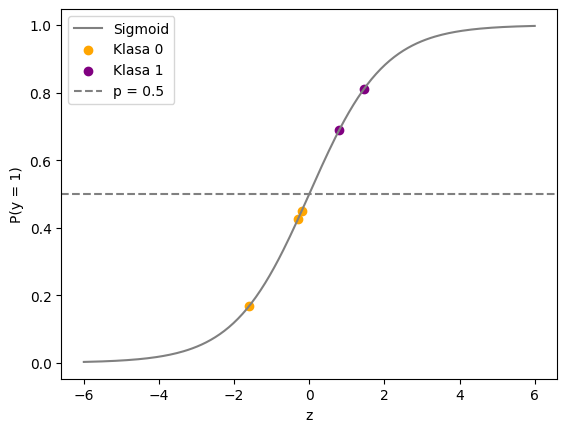

In [46]:
import matplotlib.pyplot as plt
import math

def sigmoid(z: float | NDArray[Any]) -> NDArray[Any]:
  # stwierdziłem, że zadeklaruję lambdę, bo to się powtarza w 2 miejscach
  # chociarz rozumiem, że w tej funkcji jest to całkiem zbędne
  sigma = lambda x: 1/(1+np.exp(-x))

  return sigma(z) if type(z) is float else sigma(np.array(z))

def predict_proba(X: NDArray[Any], w: NDArray[np.float64], b) -> float:
  return sigmoid((X @ w) + b)

proba = predict_proba(X, w, b)

z_grid = np.linspace(-6, 6, 200)
sigma_grid = sigmoid(z_grid)

fig, ax = plt.subplots()

ax.plot(z_grid, sigma_grid, color="gray", label="Sigmoid")
ax.scatter(z[y_c == 0], proba[y_c == 0], color="orange", label="Klasa 0")
ax.scatter(z[y_c == 1], proba[y_c == 1], color="purple", label="Klasa 1")

ax.axhline(0.5, color="gray", linestyle="--", label="p = 0.5")

ax.set_xlabel("z")
ax.set_ylabel("P(y = 1)")
ax.legend()

plt.show()

In [47]:
# TEST
assert sigmoid(0) == 0.5 and np.allclose(sigmoid(np.array([-100.0, 100.0])), [0, 1])
assert np.allclose(proba, [0.42556, 0.80999, 0.16798, 0.68997, 0.45017], atol=1e-4)
print("A3 OK")

A3 OK


### Krok 4. Próg decyzyjny: z prawdopodobieństwa robimy decyzję

Ostatni krok to porównanie $\hat{p}$ z progiem: $\hat{y} = 1$, gdy $\hat{p} \ge \text{próg}$, w przeciwnym razie $\hat{y} = 0$.

**Ważne:** próg **nie jest uczony**. Wybiera go człowiek, w zależności od tego, który błąd jest w danym zastosowaniu droższy:
- **niski próg** → model częściej mówi „1”: mniej przeoczeń (FN), więcej fałszywych alarmów (FP), czyli wyższy recall i niższa precision;
- **wysoki próg** → model mówi „1” tylko, gdy jest pewny: mniej FP, więcej FN.

Przypomnij sobie pytanie o wykrywanie choroby z mini-eksperymentu w Lab 1: to jest właśnie to miejsce, w którym tę decyzję się podejmuje.

### Zadanie A4. Decyzja i jej ocena
1. Napisz funkcję `predict(X, w, b, threshold=0.5)`, która zwraca etykiety 0/1 jako tablicę liczb całkowitych (`.astype(int)`).
2. Policz `y_hat = predict(X, w, b)` oraz `binary_metrics(y_c, y_hat)`.
3. Powtórz dla progu 0.7 (`y_hat_07`) i progu 0.4 (`y_hat_04`).
4. Zbierz wyniki w małej tabeli (wiersz = próg; kolumny `precision`, `recall`) i odpowiedz na pytania pod spodem.

In [48]:
import pandas as pd

def predict(X: NDArray[Any], w: NDArray[np.float64], b, threshold: float | int=0.5) -> list[int]:
  p = sigmoid((X @ w) + b)
  res = p >= threshold
  return res.astype(int)

thresholds = [0.4, 0.5, 0.7]

y_hat = predict(X, w, b)
y_hat_07 = predict(X, w, b, thresholds[2])
y_hat_04 = predict(X, w, b, thresholds[0])


y_hat_metrics = binary_metrics(y_c, y_hat)
y_hat_metrics_07 = binary_metrics(y_c, y_hat_07)
y_hat_metrics_04 = binary_metrics(y_c, y_hat_04)

print("0.4", y_hat_metrics_04)
print("0.5", y_hat_metrics)
print("0.7", y_hat_metrics_07)

df = pd.DataFrame([
  {"precision": y_hat_metrics_04["precision"], "recall": y_hat_metrics_04["recall"]},
  {"precision": y_hat_metrics["precision"], "recall": y_hat_metrics["recall"]},
  {"precision": y_hat_metrics_07["precision"], "recall": y_hat_metrics_07["recall"]}
], index=thresholds)

df

0.4 {'accuracy': 0.6, 'precision': 0.5, 'recall': 1.0, 'f1': 0.6666666666666666, 'TP': 2, 'FP': 2, 'TN': 1, 'FN': 0}
0.5 {'accuracy': 1.0, 'precision': 1.0, 'recall': 1.0, 'f1': 1.0, 'TP': 2, 'FP': 0, 'TN': 3, 'FN': 0}
0.7 {'accuracy': 0.8, 'precision': 1.0, 'recall': 0.5, 'f1': 0.6666666666666666, 'TP': 1, 'FP': 0, 'TN': 3, 'FN': 1}


,precision,recall
0.4,0.5,1.0
0.5,1.0,1.0
0.7,1.0,0.5


In [49]:
# TEST
assert list(y_hat) == [0, 1, 0, 1, 0] and list(y_hat_07) == [0, 1, 0, 0, 0]
assert list(y_hat_04) == [1, 1, 0, 1, 1]
assert np.issubdtype(y_hat.dtype, np.integer)
print("A4 OK")

A4 OK


**Pytania:**
1. Co dzieje się z precision i recall, gdy podnosisz próg z 0.4 do 0.7? Wskaż na wykresie z A3, który przykład „zmienia stronę” przy każdej zmianie progu.
2. Zmień znak pierwszej wagi (`w[0] = -1.0`) w głowie albo w osobnej komórce. Co stanie się z predykcjami? Co to mówi o znaczeniu znaku wagi?
3. Przy progu 0.5 model jest tu bezbłędny. Dlaczego nie świadczy to jeszcze o tym, że jest dobry? (Wskazówka: ile mamy przykładów i skąd wzięły się wagi?)

*Twoja odpowiedź:*
> 1. Przy podnoszeniu progu z 0.4 do 0.7 `precision` się podnosi, lecz `recall` maleje. Punkty `0.45017` i `0.68997` zmieniają stronę.
2. Zmiana znaku pierwszej wagi zmieni kierunek wpływu pierwszej cechy na wynik liniowy `z`, a przez sigmoidę rónież na prawdopodobiweństwo klasy 1. Konkretne zmiany zależą od danych, pozostałych wag i biasu. Dodatnia waga zwięsza wynik, a ujemna go zmniejsza. Sigmoida przekłada ten wynik na prawdopodobiweństwo klasy 1.
3. Bezbłędna klasyfikacja pięciu przykładów nie dowodzi, że model jest dobry, ponieważ próba jest bardzo mała. Potrzebna jest ocena na niewidzianych przykładach.

---
## Część B. Titanic: pierwszy klasyfikator na prawdziwych danych

Zbiór opisuje 891 pasażerów Titanica. Zadanie klasyfikacji binarnej: przewidzieć kolumnę `survived` (1 = przeżył/a, 0 = nie).

| Kolumna | Znaczenie |
|---|---|
| `survived` | **etykieta**: 1 = przeżył/a, 0 = nie |
| `pclass` | klasa podróży: 1, 2 lub 3 |
| `sex` | płeć: `"male"` / `"female"` |
| `age` | wiek w latach (są braki!) |
| `fare` | cena biletu |
| `embarked` | port zaokrętowania: S, C, Q |

W tej części **nie uczymy jeszcze żadnego modelu**. Sprawdzamy, ile da się osiągnąć prostą regułą i jak taki wynik uczciwie ocenić.

In [50]:
import seaborn as sns

df = sns.load_dataset("titanic")
df = df[["survived", "pclass", "sex", "age", "fare", "embarked"]].copy()

df.head()

,survived,pclass,sex,age,fare,embarked
0,0,3,male,22.0,7.2500,S
1,1,1,female,38.0,71.2833,C
2,1,3,female,26.0,7.9250,S
3,1,1,female,35.0,53.1000,S
4,0,3,male,35.0,8.0500,S


### Zadanie B1. Poznaj dane
1. Wypisz liczbę wierszy i kolumn oraz typy kolumn (`df.shape`, `df.dtypes`).
2. Policz liczbę brakujących wartości w każdej kolumnie (`df.isna().sum()`); liczbę braków w kolumnie `age` zapisz w `n_missing_age`.
3. Policz udział osób, które przeżyły, i zapisz go w `p_survived`. To jest **częstość bazowa** klasy pozytywnej, czyli dokładnie parametr $p$ z mini-eksperymentu w Lab 1.
4. Jaką accuracy osiągnie na tym zbiorze model „nikt nie przeżył” (zawsze-zero)? Najpierw policz na kartce, potem sprawdź funkcją `binary_metrics` i zapisz w `acc_baseline`.

In [51]:
print(df.shape)
print(df.dtypes, "\n")
# print(df.isna().sum())

n_missing_age = df['age'].isna().sum()
p_survived = df["survived"].value_counts(normalize=True)[1]
print(n_missing_age, p_survived, sep="\n")

acc_baseline = binary_metrics(np.zeros((len(df["survived"]), ), dtype=np.int8),
  df["survived"]
)["accuracy"]

(891, 6)
survived      int64
pclass        int64
sex          object
age         float64
fare        float64
embarked     object
dtype: object 

177
0.3838383838383838


In [52]:
# TEST
assert n_missing_age == 177
assert abs(p_survived - 0.3838) < 1e-3 and abs(acc_baseline - (1 - p_survived)) < 1e-9
print("B1 OK")

B1 OK
